In [28]:
import os
from typing import List, Union, Optional, Dict
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import matplotlib.pyplot as plt

def _csv_to_points_gdf(
    csv_path: str,
    lon_col: str = "lon",
    lat_col: str = "lat",
    csv_crs: str = "EPSG:4326",
) -> gpd.GeoDataFrame:
    df = pd.read_csv(csv_path)
    if lon_col not in df.columns or lat_col not in df.columns:
        raise ValueError(f"{csv_path} 缺少列: '{lon_col}' / '{lat_col}'")
    gdf = gpd.GeoDataFrame(
        df,
        geometry=[Point(xy) for xy in zip(df[lon_col], df[lat_col])],
        crs=csv_crs
    )
    return gdf

def _add_north_arrow(ax, size: float = 0.08, pad: float = 0.03):
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    dx, dy = x1 - x0, y1 - y0
    x = x1 - dx * pad
    y = y0 + dy * pad        # 锚点放在下方更自然
    L = dy * size
    ax.annotate(
        "", 
        xy=(x, y + L),       # 改成向上箭头
        xytext=(x, y),
        arrowprops=dict(arrowstyle="simple", linewidth=1.1, color="black", facecolor="black")
    )
    ax.text(x, y + L + dy * 0.01, "N", ha="center", va="bottom", fontsize=10, weight="bold")

def overlay_csv_points_on_shp(
    shp_path: str,
    csv_paths: Union[str, List[str]],
    lon_col: str = "lon",
    lat_col: str = "lat",
    csv_crs: str = "EPSG:4326",
    colors: Optional[List[str]] = None,
    labels: Optional[List[str]] = None,
    out_path: Optional[str] = None,
    figsize=(7, 7),
    dpi: int = 300,
    point_size: float = 6.0,
    alpha: float = 0.9,
    edge_color: str = "black",
    edge_lw: float = 0.6,
    facecolor: str = "none",
    tight: bool = True,
):
    """
    将一个或多个 CSV 点(经纬度)叠加到一个 shapefile 上:
    - 自动将点投影到 shapefile 的 CRS
    - 可指定颜色/图例
    - 可保存图片，也可只返回对象

    返回:
        base_gdf: 底图 GeoDataFrame
        points_gdfs: List[GeoDataFrame] (与 csv_paths 一一对应，已转到底图 CRS)
        fig, ax: matplotlib 图对象
    """
    # 规范化输入
    if isinstance(csv_paths, str):
        csv_paths = [csv_paths]
    n = len(csv_paths)

    base_gdf = gpd.read_file(shp_path)
    if base_gdf.empty:
        raise ValueError("Shapefile 为空")
    base_crs = base_gdf.crs

    # 颜色与图例
    if colors is None:
        # 给多个图层默认配色
        default = ["#d62728", "#1f77b4", "#2ca02c", "#9467bd", "#ff7f0e",
                   "#8c564b", "#17becf", "#7f7f7f", "#bcbd22", "#e377c2"]
        colors = [default[i % len(default)] for i in range(n)]
    if labels is None:
        labels = [os.path.splitext(os.path.basename(p))[0] for p in csv_paths]
    if len(colors) != n or len(labels) != n:
        raise ValueError("colors / labels 长度需要与 csv_paths 一致")

    # 读入并投影点
    points_gdfs: List[gpd.GeoDataFrame] = []
    for p in csv_paths:
        gdf_pts = _csv_to_points_gdf(p, lon_col, lat_col, csv_crs)
        if base_crs is not None and gdf_pts.crs != base_crs:
            gdf_pts = gdf_pts.to_crs(base_crs)
        points_gdfs.append(gdf_pts)

    # 画图
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    base_gdf.plot(ax=ax, edgecolor=edge_color, facecolor=facecolor, linewidth=edge_lw)

    handles = []
    for gdf_pts, color, label in zip(points_gdfs, colors, labels):
        if not gdf_pts.empty:
            g = gdf_pts.plot(ax=ax, markersize=point_size, color=color, alpha=alpha, label=label)
            handles.append(g)

    ax.set_xlim(*base_gdf.total_bounds[[0, 2]])
    ax.set_ylim(*base_gdf.total_bounds[[1, 3]])
    ax.set_axis_off()
    _add_north_arrow(ax)

    if n > 1:
        ax.legend(frameon=False, loc="lower left")

    if tight:
        plt.tight_layout()

    if out_path:
        os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
        fig.savefig(out_path, dpi=dpi, bbox_inches="tight", pad_inches=0.05)

    return base_gdf, points_gdfs, fig, ax

/var/folders/g4/7p7jhdhs7n13ct9qwch888v80000gn/T/ipykernel_14711/3041241510.py:30: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.annotate(


(   OBJECTID  Join_Count  TARGET_FID  Edit_Seq GEP_Check   Area_54009  \
 0         1           2        1961         2      None  3178.945023   
 
    Region_Typ Region_Nam Name  Lake_ID  v1_Lake_ID  v11_LakeID  ORIG_FID  \
 0           5       东部平原  鄱阳湖        2           2           2         0   
 
    Shape_Leng   Shape_Area           c         y  \
 0   25.672853  3071.252772  116.278258  29.15302   
 
                                             geometry  
 0  POLYGON Z ((116.19636 29.70962 0, 116.19582 29...  ,
 [    beam         lon        lat  h_te_best_fit  h_te_interp  h_te_mean  \
  0   gt1l  116.354225  29.217870       6.122921     5.952517   6.477689   
  1   gt1l  116.354120  29.216970       7.648104     7.563981   7.678086   
  2   gt1l  116.354020  29.216070       8.082430     8.074228   7.946746   
  3   gt1l  116.352690  29.204367       5.037290     5.047412   5.034983   
  4   gt1l  116.352590  29.203468       5.002797     5.006991   5.005706   
  5   gt1l  116.352

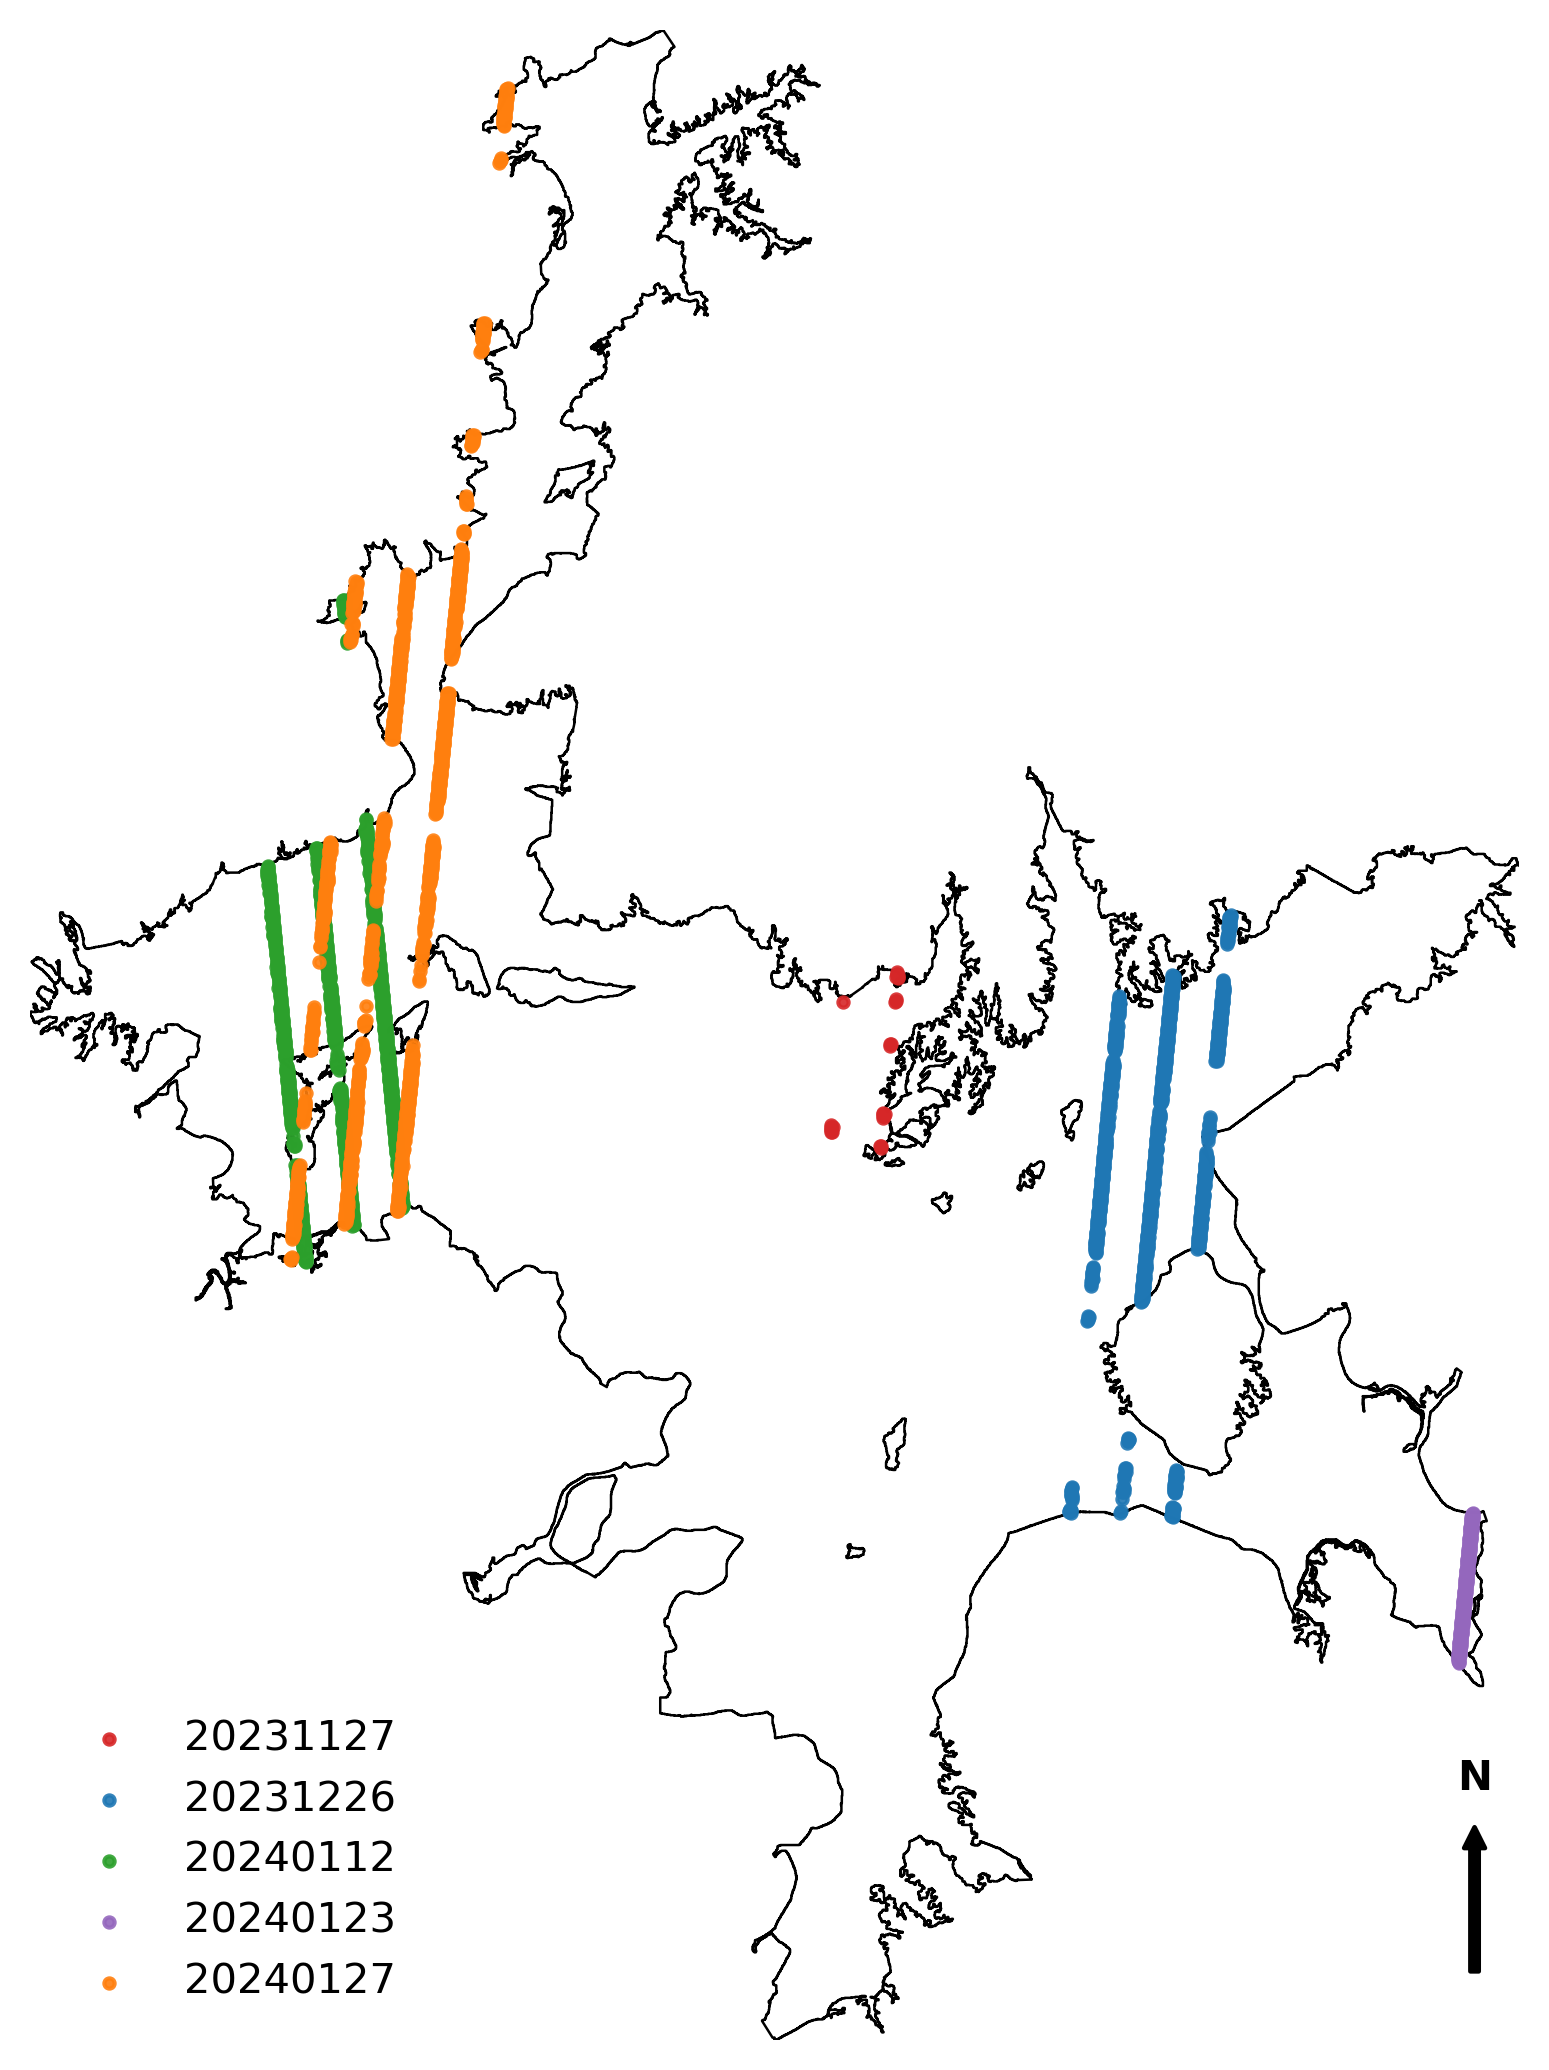

In [33]:
overlay_csv_points_on_shp(
    shp_path="/Users/a1-6/Self_program/underground_water/鄱阳湖最大边界/Poyang_Lakes1.shp",

    
    #2019-2020
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20191106011604_06130506_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20191119123516_08190502_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20191204235205_10550506_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20200131210410_05520606_007_01_Rule1_full.csv",  
    # ],

    #2020-2021
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20201103075511_06130906_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20201231050721_01101006_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20210117161809_03771002_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20210129034327_05521006_007_01_Rule1_full.csv",  
    # ],
    
    #2021-2022
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20211115015401_08191302_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20211130131051_10551306_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20211218002145_13221302_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20211229114654_01101406_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20220102113835_01711406_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20220111230607_03161402_007_01_Rule1_full.csv",
    # ],
    
    #2022-2023
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20221128195015_10551706_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20221212070923_12611702_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20230110054523_03161802_007_01_Rule1_full.csv",
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20230129165410_06131806_007_01_Rule1_full.csv",
    # ],
    #2022 12月
    # csv_paths=[
    #     "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20221212070923_12611702_007_01_Rule1_full.csv",
    # ], 
    
    #2023-2024
    csv_paths=[
        "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20231127022828_10552106_007_01_Rule1_full.csv",
        "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20231226010431_01102206_007_01_Rule1_full.csv",
        "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20240112121516_03772202_007_01_Rule1_full.csv",
        "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20240123234022_05522206_007_01_Rule1_full.csv",
        "/Users/a1-6/Self_program/underground_water/controlpoints_out/ATL08_20240127233201_06132206_007_01_Rule1_full.csv",        
    ],
    
   
    # labels=["20191106", "20191119", "20191204","20200131"], 
    # labels=["20211115", "2021113", "20211218","20211229","20220102","20220111"], 
    # labels=["20221128", "20221212", "20230110","20230129"], 
    # labels=["20221212"], 
    labels=["20231127", "20231226", "20240112","20240123","20240127"],
    # 2019-2020
    # out_path="/Users/a1-6/Self_program/underground_water/2019_2020_11_12_1.png"
    #2020-2021
    # out_path="/Users/a1-6/Self_program/underground_water/2020_2021_11_12_1.png"
    # out_path="/Users/a1-6/Self_program/underground_water/2022_2023_11_12_1.png"
    # 2022 12
    # out_path="/Users/a1-6/Self_program/underground_water/2022_12.png"
    out_path="/Users/a1-6/Self_program/underground_water/2023_2024_11_12_1.png"
    
)